# Decision Tree Workflow

This notebook covers decision tree model selection and a manual ensemble workflow that illustrates why many diverse trees can outperform a single tree.

## Workflow Overview

**Objective:** train interpretable nonlinear classifiers and reduce variance through majority voting.

**Dataset:** synthetic moons classification data.

**Primary metric:** classification accuracy on held-out test data.

**Validation strategy:** grid search with cross-validation for tree hyperparameters; final model is refit and evaluated on test data.

**Production mindset:** tree visualization helps explain model behavior, while the manual forest demonstrates the mechanics behind bagging-style ensembles.

## Stage 0 - Environment Setup

Import tree models, validation tools, plotting utilities, and helper functions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mode

from sklearn.base import clone
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, ShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## Stage 1 - Fine-Tuned Decision Tree

Generate nonlinear classification data, visualize the distribution, tune decision-tree hyperparameters, and inspect the resulting tree structure.

Steps:

1. Generate `10,000` noisy moons samples.
2. Split into train/test sets.
3. Use `GridSearchCV` to tune a `DecisionTreeClassifier`.
4. Train the best tree and evaluate it on the test set.

In [3]:
X_moons, y_moons = make_moons(n_samples=10_000, noise=0.4, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_moons,
)

X_train.shape, X_test.shape, y_train.mean(), y_test.mean()

((8000, 2), (2000, 2), 0.5, 0.5)

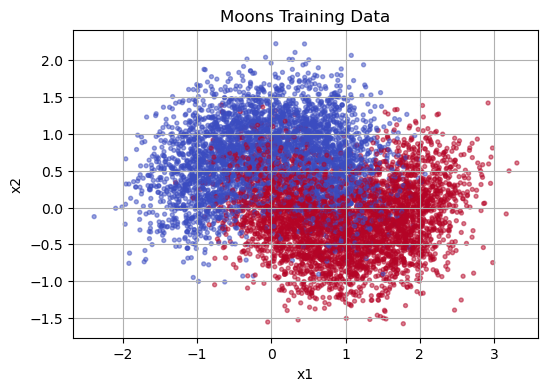

In [4]:
plt.figure(figsize=(6, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=8, cmap="coolwarm", alpha=0.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Moons Training Data")
plt.grid(True)
plt.show()

In [5]:
tree_param_grid = {
    "max_leaf_nodes": list(range(2, 100)),
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 3, 4],
}

tree_grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    tree_param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
)

tree_grid_search.fit(X_train, y_train)

tree_grid_search.best_params_, tree_grid_search.best_score_

Fitting 3 folds for each of 1176 candidates, totalling 3528 fits


({'max_depth': None, 'max_leaf_nodes': 20, 'min_samples_split': 2},
 0.8581246830267747)

In [6]:
best_tree_clf = clone(tree_grid_search.best_estimator_)
best_tree_clf.fit(X_train, y_train)

y_pred_tree = best_tree_clf.predict(X_test)
tree_test_accuracy = accuracy_score(y_test, y_pred_tree)

tree_test_accuracy

0.853

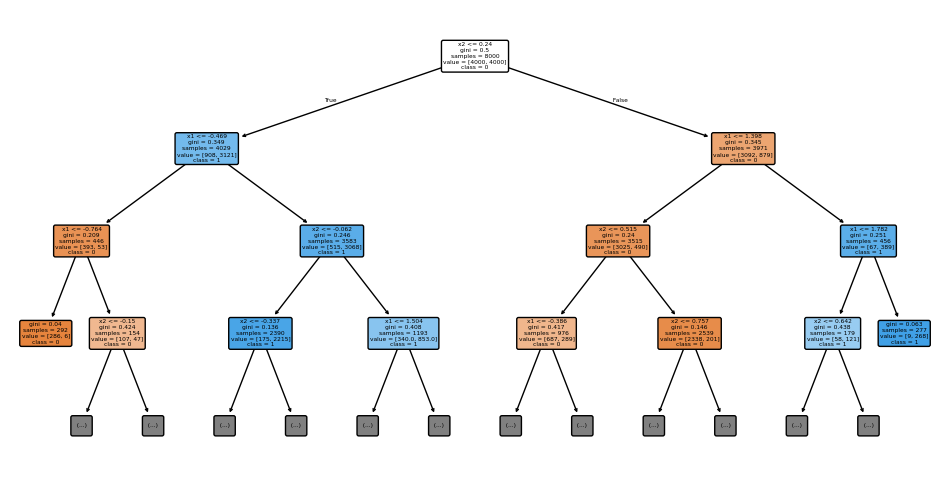

In [7]:
plt.figure(figsize=(12, 6))
plot_tree(
    best_tree_clf,
    filled=True,
    rounded=True,
    max_depth=3,
    feature_names=["x1", "x2"],
    class_names=["0", "1"],
)
plt.show()

## Stage 2 - Manual Majority-Vote Forest

Train many small trees on random subsets and combine predictions with majority vote to reduce variance.

We now build a simple random forest manually:

1. Create 1,000 random subsets of the training set.
2. Train one decision tree on each subset.
3. Predict the test set with every tree.
4. Use majority vote for the final prediction.
5. Compare the majority-vote accuracy with the single best tree.

In [8]:
n_trees = 1_000
n_instances = 100

mini_sets = []
shuffle_split = ShuffleSplit(
    n_splits=n_trees,
    train_size=n_instances,
    random_state=RANDOM_STATE,
)

for mini_train_index, _ in shuffle_split.split(X_train):
    X_mini_train = X_train[mini_train_index]
    y_mini_train = y_train[mini_train_index]
    mini_sets.append((X_mini_train, y_mini_train))

len(mini_sets), mini_sets[0][0].shape, mini_sets[0][1].shape

(1000, (100, 2), (100,))

In [9]:
forest = []
individual_tree_accuracies = []

for X_mini_train, y_mini_train in mini_sets:
    tree_clf = clone(tree_grid_search.best_estimator_)
    tree_clf.fit(X_mini_train, y_mini_train)
    forest.append(tree_clf)

    y_pred = tree_clf.predict(X_test)
    individual_tree_accuracies.append(accuracy_score(y_test, y_pred))

individual_tree_accuracies = np.array(individual_tree_accuracies)

describe_individual_trees = pd.Series(individual_tree_accuracies).describe()
describe_individual_trees

count    1000.000000
mean        0.798221
std         0.025705
min         0.672000
25%         0.782500
50%         0.801000
75%         0.817000
max         0.858500
dtype: float64

In [10]:
y_pred_forest = np.array([tree.predict(X_test) for tree in forest])
majority_votes = mode(y_pred_forest, axis=0, keepdims=False).mode

forest_test_accuracy = accuracy_score(y_test, majority_votes)

pd.Series({
    "single_best_tree_test_accuracy": tree_test_accuracy,
    "mean_individual_small_tree_accuracy": individual_tree_accuracies.mean(),
    "manual_forest_majority_vote_accuracy": forest_test_accuracy,
    "forest_improvement_over_single_tree": forest_test_accuracy - tree_test_accuracy,
})

single_best_tree_test_accuracy          0.853000
mean_individual_small_tree_accuracy     0.798221
manual_forest_majority_vote_accuracy    0.863500
forest_improvement_over_single_tree     0.010500
dtype: float64

In [11]:
pd.DataFrame({
    "true_label": y_test[:20],
    "single_tree_prediction": y_pred_tree[:20],
    "forest_majority_vote": majority_votes[:20],
    "forest_correct": majority_votes[:20] == y_test[:20],
})

,true_label,single_tree_prediction,forest_majority_vote,forest_correct
0,0,0,0,True
1,1,1,1,True
2,0,0,0,True
3,1,1,1,True
4,0,0,0,True
5,0,1,1,False
6,0,1,1,False
7,1,1,1,True
8,0,0,0,True
9,1,1,1,True


## Workflow Summary and Next Steps

Summarize single-tree behavior, ensemble gains, and what would change when using `RandomForestClassifier` directly.

The decision-tree experiments are complete.

Key ideas:

- unrestricted decision trees on balanced data have depth around `log2(m)`
- CART reduces weighted impurity, not necessarily every individual child impurity
- decreasing `max_depth` regularizes an overfitting tree
- scaling usually does not matter for decision trees
- CART training is roughly proportional to `n_features * n_instances * log(n_instances)`
- majority voting over many diverse trees reduces variance and behaves like a random forest